## 6. Ethics: Disparate impact audit

Fairness audit of the locked model from 4_modelling.
The audit asks :
- Does the model flag deprived/young/diverse areas more?
- Are the false alarms balanced across those groups? (FPR by tertile)
- Is the disparity really about ethnicity, or deprivation?
- Which features drive the model?



In [1]:
import os
import warnings

import numpy as np    
import pandas as pd    
import matplotlib.pyplot as plt   
from scipy.stats import spearmanr, chi2_contingency
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
RANDOM_STATE=100
rng=np.random.default_rng(RANDOM_STATE)

### Paths & filenames

In [2]:
SCRIPT_DIR=os.path.dirname(os.path.abspath('__file__'))
BASE=os.path.dirname(SCRIPT_DIR)
DATA=os.path.join(BASE, 'Data')
OUT_DIR=os.path.join(BASE, 'Ethics_outputs')
os.makedirs(OUT_DIR, exist_ok=True)

MODEL_CSV=os.path.join(DATA, 'crime_features_model.csv')
ETHNIC_CSV=os.path.join(DATA, 'Ethnic_group.csv')
AGE_CSV=os.path.join(DATA, 'Age_by_5_year.csv')


### Loading modelling data, rebuilding taret, training the locked model

In [3]:
df=pd.read_csv(MODEL_CSV)
#Sorting by area and month
df=df.sort_values(['LSOA code', 'Month']).reset_index(drop=True)
#Building the forecasting target (next month's hotspot target)
df['hotspot_next']=df.groupby('LSOA code')['hotspot'].shift(-1)
#Dropping each area's last month
df=df.dropna(subset=['hotspot_next']).copy()
df['hotspot_next']=df['hotspot_next'].astype(int)

#Features
FEATURE_COLS=[
    'crime_lag_1', 'crime_lag_2', 'crime_lag_3',
    'crime_change', 'crime_rolling_3', 'hotspot_lag_1',
    'spatial_lag_crime', 'spatial_lag_hotspot',
    'month_sin', 'month_cos',
    'temp_mean', 'temp_max', 'temp_min', 'rainfall_total', 'rainfall_days',
    'school_holiday_days', 'bank_holiday_days',
    'imd_decile', 'income_decile', 'employment_decile', 'education_decile',
    'health_decile', 'housing_decile', 'living_env_decile',
    'la_Hartlepool', 'la_Middlesbrough', 'la_Redcar and Cleveland',
    'la_Stockton-on-Tees'
]

#Temporal split, last 8 months - test, everything before - train
N_TEST_MONTHS=8
months=sorted(df['Month'].unique())
train=df[df['Month'].isin(months[:-N_TEST_MONTHS])].copy()
test=df[df['Month'].isin(months[-N_TEST_MONTHS:])].copy()
y_train=train['hotspot_next']

#Training the locked model (from 4_modelling)
SPW=(y_train==0).sum()/(y_train==1).sum()
CURRENT_PARAMS={'n_estimators':400, 'max_depth':4, 'learning_rate':0.03,
                'subsample':0.8, 'colsample_bytree':0.8}
THRESHOLD=0.725

model=XGBClassifier(**CURRENT_PARAMS, scale_pos_weight=SPW,
                    random_state=RANDOM_STATE, eval_metric='logloss')
model.fit(train[FEATURE_COLS], y_train)

test=test.copy()
#Getting the probability of being a hotspot next month, for each test row
test['proba']=model.predict_proba(test[FEATURE_COLS])[:,1]
#Converting probabilities into 0/1 predictions
test['pred']=(test['proba']>=THRESHOLD).astype(int)

print('Model trained.')
print(f'Test rows: {len(test):,} test accuracy: '
      f'{accuracy_score(test["hotspot_next"], test["pred"]):.3f}')




Model trained.
Test rows: 2,872 test accuracy: 0.952


### Per-LSOA outcomes on the test set

Fore ach area, counting how often the model flagged it, how often it truly was a hotspot, and its FP/FN/TP/TN.

In [4]:
#Labelling each test row's prediction
#False positive
test['is_fp']=((test['pred']==1) & (test['hotspot_next']==0)).astype(int)
#False negative
test['is_fn']=((test['pred']== 0) & (test['hotspot_next'] == 1)).astype(int)
#True positive
test['is_tp']=((test['pred'] == 1) & (test['hotspot_next'] == 1)).astype(int)
#True negative
test['is_tn']=((test['pred'] == 0) & (test['hotspot_next'] == 0)).astype(int)

#Summarising per area across the 8 test motnhs
lsoa=test.groupby('LSOA code').agg(
    #How often the model flagged thi area
    pred_rate=('pred', 'mean'),
    #How often this area was truly a hotspot
    actual_rate=('hotspot_next', 'mean'),
    n_months=('pred', 'size'),
    #counts of each outcome
    fp=('is_fp', 'sum'), fn=('is_fn', 'sum'),
    tp=('is_tp', 'sum'), tn=('is_tn', 'sum'),
    imd_decile=('imd_decile', 'first'),
).reset_index()

print(f"Per-LSOA outcome table: {len(lsoa)} LSOAs")




Per-LSOA outcome table: 359 LSOAs


### PARSING Ethnic_group.csv --> non-White & (per LSOA) (Census 2021)

Computing the % of non-white residents per area

In [ ]:
#Loading the Census ethnicity file, skipping the header
eth=pd.read_csv(ETHNIC_CSV, skiprows=7)

#Keeping the rows only with valid LSOA code
eth=eth[eth['mnemonic'].astype(str).str.match(r'^E01', na=False)].copy()

#Calculating the non-white share of residents for each area
ETH_TOTAL='Total: All usual residents'
eth['non_white_pct']=(eth[ETH_TOTAL] - eth['White'])/eth[ETH_TOTAL]*100.0

#High level minority group shares 
for grp, col in [('asian_pct', 'Asian, Asian British or Asian Welsh'),
                 ('black_pct', 'Black, Black British, Black Welsh, Caribbean or African'),
                 ('mixed_pct', 'Mixed or Multiple ethnic groups'),
                 ('other_eth_pct', 'Other ethnic group')]:
    eth[grp]=eth[col]/eth[ETH_TOTAL]*100.0

eth_small=eth[['mnemonic', 'non_white_pct', 'asian_pct', 'black_pct',
                 'mixed_pct', 'other_eth_pct']].rename(
    columns={'mnemonic': 'LSOA code'})

print("Ethnic parse:")
print(f"LSOAs: {len(eth_small)}")
print(f"non_white_pct median {eth_small['non_white_pct'].median():.2f} "
      f"\nIQR {eth_small['non_white_pct'].quantile(.25):.2f} - "
      f"{eth_small['non_white_pct'].quantile(.75):.2f} "
      f"\nmax {eth_small['non_white_pct'].max():.2f}")

print("non-white % has a low median but a high max")
print("--> diversity is concenrated in a few areas")


Ethnic parse:
LSOAs: 359
non_white_pct median 3.84 
IQR 1.97 - 8.07 
max 73.30
non-white % has a low median but a high max
--> diversity is concenrated in a few areas


### PARSING Age_by_5_year.csv --> young-adult (15-29) (Census 2021)

Computing the % of young adults (15-29)

In [6]:
#Loading the census Age file
age=pd.read_csv(AGE_CSV)
age.columns=[c.strip() for c in age.columns]

AGE_LSOA='Lower Layer Super Output Areas Code'
AGE_LABEL='Lower Layer Super Output Areas Label'
AGE_CODE='Age (B) (18 categories) Code'

#Filtering to Cleveland LAs
cleveland=age[age[AGE_LABEL].str.contains(
    'Hartlepool|Middlesbrough|Redcar and Cleveland|Stockton-on-Tees',
    na=False)].copy()
#total population per area
tot_age=cleveland.groupby(AGE_LSOA)['Count'].sum().rename('pop_total')
#young adults (15-29)
young=(cleveland[cleveland[AGE_CODE].isin([4,5,6])]
       .groupby(AGE_LSOA)['Count'].sum().rename('young_count'))
#Calculating the young-adult share
age_small=pd.concat([tot_age, young], axis=1).reset_index()
age_small['young_15_29_pct']=age_small['young_count'] / age_small['pop_total']*100.00
#Renaming columns to match, storing them
age_small=age_small.rename(columns={AGE_LSOA: 'LSOA code'})[
    ['LSOA code', 'young_15_29_pct', 'pop_total']
]


print("\nAge parse:")
print(f"Cleveland LSOAs: {len(age_small)}")
print(f"young_15_29_pct median {age_small['young_15_29_pct'].median():.2f}, "
      f"min {age_small['young_15_29_pct'].min():.2f}, "
      f"max {age_small['young_15_29_pct'].max():.2f}")





Age parse:
Cleveland LSOAs: 359
young_15_29_pct median 16.42, min 8.57, max 58.53


### DEprivation direction + merging all axes onto the outcome table

Joining the demographics onto per-area outcomes and building a "more-deprived-is-higher" axis 

In [7]:
lsoa=lsoa.merge(eth_small, on='LSOA code', how='left')
lsoa=lsoa.merge(age_small, on='LSOA code', how='left')

matched_eth=lsoa['non_white_pct'].notna().sum()
matched_age=lsoa['young_15_29_pct'].notna().sum()

print(f"\nMerge match: ethnicity {matched_eth}/{len(lsoa)}, "
      f"age {matched_age}/{len(lsoa)}")



#Building a "more-deprived-is-higher" axis --> all 3 axes became
#comparable (higher value = more of the disadvantaged attribute)

# IoD decile 1 = most deprived, flipping it --> higher number means more deprived
lsoa['deprivation_severity'] = 11 - lsoa['imd_decile']

AXES={
    'deprivation_severity': 'Deprivation',
    'young_15_29_pct': 'Young adults 15-29 (%)',
    'non_white_pct': 'Non_White residents (%)',
}


Merge match: ethnicity 359/359, age 359/359


### Check 1: Does flagging track demogrpahics? 

Measuring 2 things for each characteristics:
- how strongly it relates to  the model's flagging
- how strongly it relates to actual recorded crime

If those numbers close, the model is simply tracking real crime patterns, not adding bias.

In [8]:
print("DISPARATE IMPACT: correlation with model flagging")
print(f"{'Axis':<28}{'rho(pred)':>11}{'rho(actual)':>13}")

impact_rows=[]

#For each demographic characteristic:
for axis, label in AXES.items():
    #Dropping areas with missing data
    sub=lsoa.dropna(subset=[axis])
    # How strongly the characteristic correlates with the model flagging an area
    rho_p=spearmanr(sub[axis], sub['pred_rate']).correlation
    #how strongly it correlates with the area's actual hotspot rate
    rho_a=spearmanr(sub[axis], sub['actual_rate']).correlation

    impact_rows.append({'axis':axis, 'rho_pred':rho_p, 'rho_actual':rho_a, 'n':len(sub)})

    print(f"{label:<28}{rho_p:>+11.3f}{rho_a:>+13.3f}")
    
#Storing results
impact_df=pd.DataFrame(impact_rows)


DISPARATE IMPACT: correlation with model flagging
Axis                          rho(pred)  rho(actual)
Deprivation                      +0.418       +0.410
Young adults 15-29 (%)           +0.419       +0.437
Non_White residents (%)          +0.300       +0.309


### Check 2: Are the false alarms balanced?

Splitting areas into thirds (tertiles) on each characteristic and measuring the FP rate on areas that were genuinely NOT hotspots.
Chi-square test checks if the difference across thirds is real or chance. If the FP rate rises with deprivation, the model is over-flagging deprived areas.

In [9]:

print('ERROR-RATE BALANCE by tertile')
print('-' *40)

balance_rows = []

#For each demographics char:
for axis, label in AXES.items():
    sub = lsoa.dropna(subset=[axis]).copy()
    #Splitting areas into 3 groups, T1=least disadvantaged, T2=most disadvantaged
    try:
        sub['tertile'] = pd.qcut(sub[axis].rank(method='first'), 3,
                             labels=['T1_low', 'T2_mid', 'T3_high'])
    #If too many share the same value (can't split equally)
    except ValueError:
        sub['tertile'] = pd.cut(sub[axis], 3,
                                labels=['T1_low', 'T2_mid', 'T3_high'])
    #counting all outcomes
    grp = sub.groupby('tertile')[['fp', 'fn', 'tp', 'tn']].sum()
    #False positive rate
    grp['FPR'] = grp['fp'] / (grp['fp'] + grp['tn']).replace(0, np.nan)
    #Flase negative rate
    grp['FNR'] = grp['fn'] / (grp['fn'] + grp['tp']).replace(0, np.nan)
    #Overall flagging rate
    grp['flag_rate'] = ((grp['fp'] + grp['tp']) /
                        grp[['fp', 'fn', 'tp', 'tn']].sum(axis=1))

    # Chi-square: is FP-vs-TN independent of tertile? (well-powered: big Ns)
    fptn = grp[['fp', 'tn']].values
    chi2, p_fp, _, _ = chi2_contingency(fptn)

    #Disparate impact ratio
    #How more often is the most disadvantaged tertile flagged compared to the least
    t1_flag = grp.loc['T1_low', 'flag_rate']
    di_ratio = (grp.loc['T3_high', 'flag_rate'] / t1_flag
                if t1_flag > 0 else np.nan)
    di_str = f'{di_ratio:.2f}' if np.isfinite(di_ratio) else 'undefined (T1 never flagged)'

    print(f'\n{label}')
    print(f"{'tertile':<10}{'flag%':>8}{'FPR':>8}{'FNR':>8}{'n_months':>10}")
    for t in ['T1_low', 'T2_mid', 'T3_high']:
        n_m = int(grp.loc[t, ['fp', 'fn', 'tp', 'tn']].sum())
        print(f"{t:<10}{grp.loc[t, 'flag_rate']*100:>7.1f}%"
              f"{grp.loc[t, 'FPR']*100:>7.1f}%"
              f"{grp.loc[t, 'FNR']*100:>7.1f}%{n_m:>10}")
    print(f"FPR chi-square p = {p_fp:.4f}  "
          f"({'differs across strata' if p_fp < 0.05 else 'no sig. difference'})")
    print(f"flagging disparate-impact ratio (T3/T1) = {di_str}")
    balance_rows.append({'axis': axis, 'fpr_T1': grp.loc['T1_low', 'FPR'],
                         'fpr_T3': grp.loc['T3_high', 'FPR'],
                         'fnr_T1': grp.loc['T1_low', 'FNR'],
                         'fnr_T3': grp.loc['T3_high', 'FNR'],
                         'fpr_chi2_p': p_fp, 'di_ratio': di_ratio})
balance_df = pd.DataFrame(balance_rows)

ERROR-RATE BALANCE by tertile
----------------------------------------

Deprivation
tertile      flag%     FPR     FNR  n_months
T1_low        0.4%    0.2%   81.8%       960
T2_mid        5.9%    1.7%   12.8%       952
T3_high      28.9%   10.5%   13.0%       960
FPR chi-square p = 0.0000  (differs across strata)
flagging disparate-impact ratio (T3/T1) = 69.25

Young adults 15-29 (%)
tertile      flag%     FPR     FNR  n_months
T1_low        0.4%    0.2%   66.7%       960
T2_mid        7.8%    2.1%   17.9%       952
T3_high      27.0%    9.8%   13.5%       960
FPR chi-square p = 0.0000  (differs across strata)
flagging disparate-impact ratio (T3/T1) = 64.75

Non_White residents (%)
tertile      flag%     FPR     FNR  n_months
T1_low        2.6%    0.6%   24.0%       960
T2_mid       10.9%    4.3%   21.2%       952
T3_high      21.7%    6.5%   11.8%       960
FPR chi-square p = 0.0000  (differs across strata)
flagging disparate-impact ratio (T3/T1) = 8.32


### Check 3: Is it about ethnicity or deprivation?

The 3 characteristics overlap in the same neighbourhoods. Checking how strongly the 3 correlated with each other. If ethnicity is only weakly linked to deprivation and its FP gradient is the shallowest of the 3, the disparity is primarly socioeconomic.

In [ ]:
print("How correlated are 3 characteristics with each other?")
axes_list=['deprivation_severity', 'young_15_29_pct', 'non_white_pct']

#Comparing every unique pair
for a in axes_list:
    for b in axes_list:
        if a < b:
            #Spearman rank correlation: how closely the 2 characteristics
            #track each other across the 359 areas
            rho=spearmanr(lsoa[a], lsoa[b], nan_policy='omit').correlation
            print(f"{a:<22} vs {b:<18} rho = {rho:+.3f}")
print("\nDeprivation and ethnicity weakly correlated --> largely separate.")
print("Combined with the shallowest FPR gradient, ethnicity's effect is mostly")
print("explained by deprivation and youth: the disparity is primarily socioeconomic.")


How correlated are 3 characteristics with each other?
deprivation_severity   vs young_15_29_pct    rho = +0.608
deprivation_severity   vs non_white_pct      rho = +0.216
non_white_pct          vs young_15_29_pct    rho = +0.448

Deprivation and ethnicity weakly correlated --> largely separate.
Combined with the shallowest FPR gradient, ethnicity's effect is mostly
explained by deprivation and youth: the disparity is primarily socioeconomic.


### SHAP

Using SHAP to explore which features drive the model's decisions, to see if the model is leaning on the deprivation inputs or on the crime-history features.
If it uses mostly past crime, then the bias comes from the crime data itself, which cannot be fixed by excluding ethnicity and age.

In [ ]:
import shap

explainer=shap.TreeExplainer(model)
#computing a SHAP value per feature per test row
sv=explainer.shap_values(test[FEATURE_COLS])
#Averaging the values
mean_abs=np.abs(sv).mean(axis=0)
#sorting
shap_imp=pd.Series(mean_abs, index=FEATURE_COLS).sort_values(ascending=False)

total=shap_imp.sum()

#Grouping features into categories
crime_hist=['crime_rolling_3','crime_lag_1','crime_lag_2','crime_lag_3','crime_change']
dep_feats=['imd_decile','income_decile','employment_decile','education_decile',
           'health_decile','housing_decile','living_env_decile']
geo_feats = ['spatial_lag_crime', 'spatial_lag_hotspot', 'la_Hartlepool',
                 'la_Middlesbrough', 'la_Redcar and Cleveland',
                 'la_Stockton-on-Tees']

print("Top 8 features driving the model:")
for f, v in shap_imp.head(8).items():
    print(f"  {f:<28}{v:.4f}  ({v/total*100:.1f}%)")

print(f"\nCrime-history features share: {shap_imp[crime_hist].sum()/total*100:.1f}%")
print(f"Deprivation features share:     {shap_imp[dep_feats].sum()/total*100:.1f}%")

print("\n-> The model runs mostly on past crime, not on the deprivation inputs.")


shap_imp.to_csv(os.path.join(OUT_DIR, '6_shap_importance.csv'))

Top 8 features driving the model:
  crime_rolling_3             2.4281  (35.3%)
  crime_lag_1                 1.4099  (20.5%)
  crime_lag_2                 0.4237  (6.2%)
  crime_change                0.4036  (5.9%)
  crime_lag_3                 0.4035  (5.9%)
  spatial_lag_crime           0.2737  (4.0%)
  month_sin                   0.1858  (2.7%)
  education_decile            0.1699  (2.5%)

Crime-history features share: 73.8%
Deprivation features share:     9.3%

-> The model runs mostly on past crime, not on the deprivation inputs.


Plot 1: Flagging vs each characteristic (predicted vs actual)

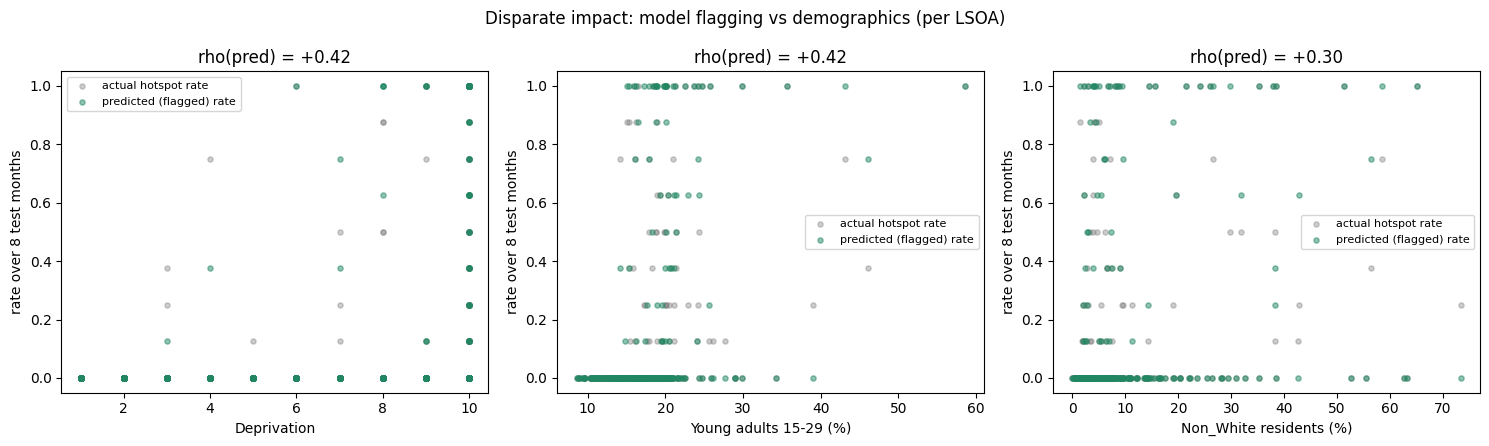

Saved Plot_1_disparate_impact.png


In [12]:
fig, axes_=plt.subplots(1,3, figsize=(15,4.5))

for ax_, (axis, label) in zip(axes_, AXES.items()):
    sub = lsoa.dropna(subset=[axis])
    ax_.scatter(sub[axis], sub['actual_rate'], s=14, alpha=0.4,
                color="#848181", label='actual hotspot rate')
    ax_.scatter(sub[axis], sub['pred_rate'], s=14, alpha=0.5,
                color="#218762", label='predicted (flagged) rate')
    ax_.set_xlabel(label)
    ax_.set_ylabel('rate over 8 test months')
    r = impact_df.loc[impact_df['axis'] == axis, 'rho_pred'].iloc[0]
    ax_.set_title(f"rho(pred) = {r:+.2f}")
    ax_.legend(fontsize=8)
fig.suptitle("Disparate impact: model flagging vs demographics (per LSOA)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Plot_1_disparate_impact.png"), dpi=150)
plt.show()

print("Saved Plot_1_disparate_impact.png")

### Plot 3: FP rate by tertile

Plot 2: FAlse Positive rate by tertile


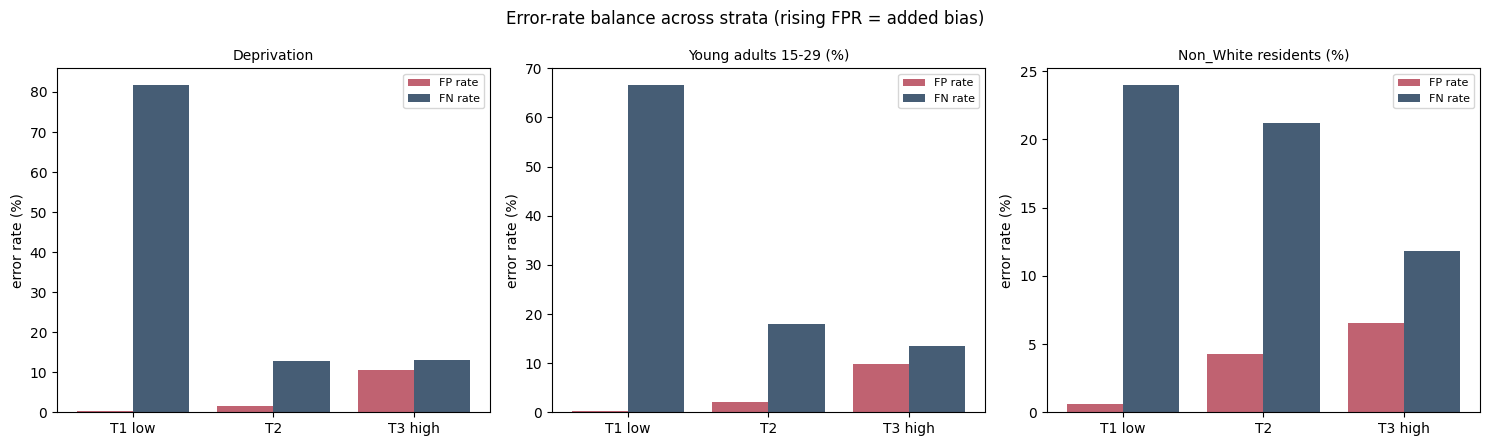

Saved Plot_2_error_balance.png 


In [13]:
print("Plot 2: FAlse Positive rate by tertile")

fig, axes_ = plt.subplots(1, 3, figsize=(15, 4.5))
xpos = np.arange(3)
for ax_, (axis, label) in zip(axes_, AXES.items()):
    sub = lsoa.dropna(subset=[axis]).copy()
    sub['tertile'] = pd.qcut(sub[axis].rank(method='first'), 3,
                             labels=['T1', 'T2', 'T3'])
    grp = sub.groupby('tertile')[['fp', 'fn', 'tp', 'tn']].sum()
    fpr = grp['fp'] / (grp['fp'] + grp['tn'])
    fnr = grp['fn'] / (grp['fn'] + grp['tp'])
    ax_.bar(xpos - 0.2, fpr.values * 100, width=0.4, color="#c06271",
            label='FP rate')
    ax_.bar(xpos + 0.2, fnr.values * 100, width=0.4, color="#465d75",
            label='FN rate')
    ax_.set_xticks(xpos)
    ax_.set_xticklabels(['T1 low', 'T2', 'T3 high'])
    ax_.set_ylabel('error rate (%)')
    ax_.set_title(label, fontsize=10)
    ax_.legend(fontsize=8)
fig.suptitle("Error-rate balance across strata (rising FPR = added bias)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Plot_2_error_balance.png'), dpi=150)
plt.show()

print("Saved Plot_2_error_balance.png ")

### Plot 3: SHAP feature importance

Plot 3: SHAP feature importance


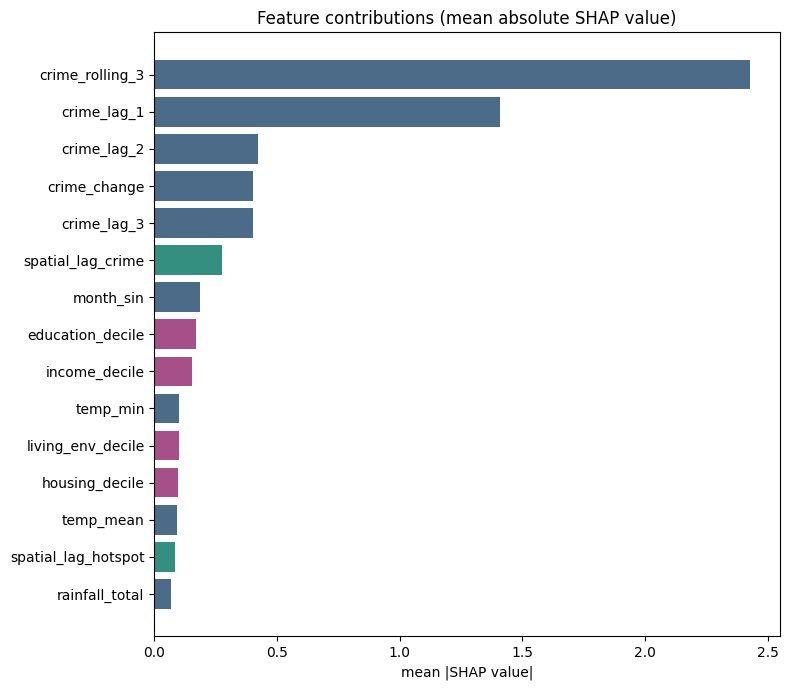

Saved Plot_3_shap_importance.png 


In [14]:
print("Plot 3: SHAP feature importance")

top = shap_imp.head(15)[::-1]
cols = []
for f in top.index:
    if f in dep_feats:
        #deprivation proxy
        cols.append("#a55089")      
    elif f in geo_feats:
        #geography proxy
        cols.append("#348f80")       
    else:
        cols.append("#4c6b89")
fig, ax_ = plt.subplots(figsize=(8, 7))
ax_.barh(top.index, top.values, color=cols)
ax_.set_xlabel("mean |SHAP value|")
ax_.set_title("Feature contributions (mean absolute SHAP value)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Plot_3_shap_importance.png'), dpi=150)
plt.show()

print("Saved Plot_3_shap_importance.png ")

### Saving the results

In [15]:
impact_df.to_csv(os.path.join(OUT_DIR, '6_impact_correlations.csv'), index=False)
balance_df.to_csv(os.path.join(OUT_DIR, '6_error_balance.csv'), index=False)
